EXPERIMENT NO. 8 (Group B) 
 
Aim: Data Cleaning and Preparation 
Problem Statement: Analyzing Customer Churn in a Telecommunications Company 
Dataset: "Telecom_Customer_Churn.csv" 
Description: The dataset contains information about customers of a telecommunications company and 
whether they have churned (i.e., discontinued their services). The dataset includes various attributes of 
the customers, such as their demographics, usage patterns, and account information. The goal is to perform 
data cleaning and preparation to gain insights into the factors that contribute to customer churn. 

Name:Aditya Rade
Roll.No:BEAD23167

Outputs:


Step 1 — Import and Load Dataset

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("Telco_Customer_Churn_Expanded.csv")

print("Dataset loaded successfully!")
print("Shape:", data.shape)
display(data.head())

Dataset loaded successfully!
Shape: (15043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Step 2 — Explore the Dataset

In [14]:
print("Dataset Information:")
data.info()

print("\nColumn Names:")
print(data.columns.tolist())

print("\nStatistical Summary:")
display(data.describe())

print("\nUnique Values:")
print(data.nunique())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15043 entries, 0 to 15042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        15043 non-null  object 
 1   gender            15043 non-null  object 
 2   SeniorCitizen     15043 non-null  int64  
 3   Partner           15043 non-null  object 
 4   Dependents        15043 non-null  object 
 5   tenure            15043 non-null  int64  
 6   PhoneService      15043 non-null  object 
 7   MultipleLines     15043 non-null  object 
 8   InternetService   15043 non-null  object 
 9   OnlineSecurity    15043 non-null  object 
 10  OnlineBackup      15043 non-null  object 
 11  DeviceProtection  15043 non-null  object 
 12  TechSupport       15043 non-null  object 
 13  StreamingTV       15043 non-null  object 
 14  StreamingMovies   15043 non-null  object 
 15  Contract          15043 non-null  object 
 16  PaperlessBilling  1

,SeniorCitizen,tenure,MonthlyCharges
count,15043.000000,15043.000000,15043.000000
mean,0.162733,32.717144,66.782433
std,0.369135,24.586526,29.711526
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,41.602308
50%,0.000000,29.000000,69.780892
75%,0.000000,56.000000,91.610379
max,1.000000,72.000000,118.750000



Unique Values:
customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      9585
TotalCharges        6531
Churn                  2
dtype: int64


Step 3 — Handle Missing Values, Duplicates & Data Types

In [15]:
# Convert TotalCharges into numeric format
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)

print("Missing values before handling:")
print(data.isnull().sum())

# Fill missing TotalCharges with median
data["TotalCharges"] = data["TotalCharges"].fillna(
    data["TotalCharges"].median()
)

print("\nMissing values after handling:")
print(data.isnull().sum())

Missing values before handling:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        19
Churn                0
dtype: int64

Missing values after handling:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0


Step 4 — Outlier Detection & Visualization

In [16]:
print("Duplicate rows before removal:", data.duplicated().sum())

data.drop_duplicates(inplace=True)

print("Duplicate rows after removal:", data.duplicated().sum())

# Remove unwanted spaces from column values
for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].str.strip()

print("\nDataset shape after cleaning:", data.shape)

Duplicate rows before removal: 0
Duplicate rows after removal: 0

Dataset shape after cleaning: (15043, 21)


Step 5 — Train-Test Split & Export Cleaned Dataset

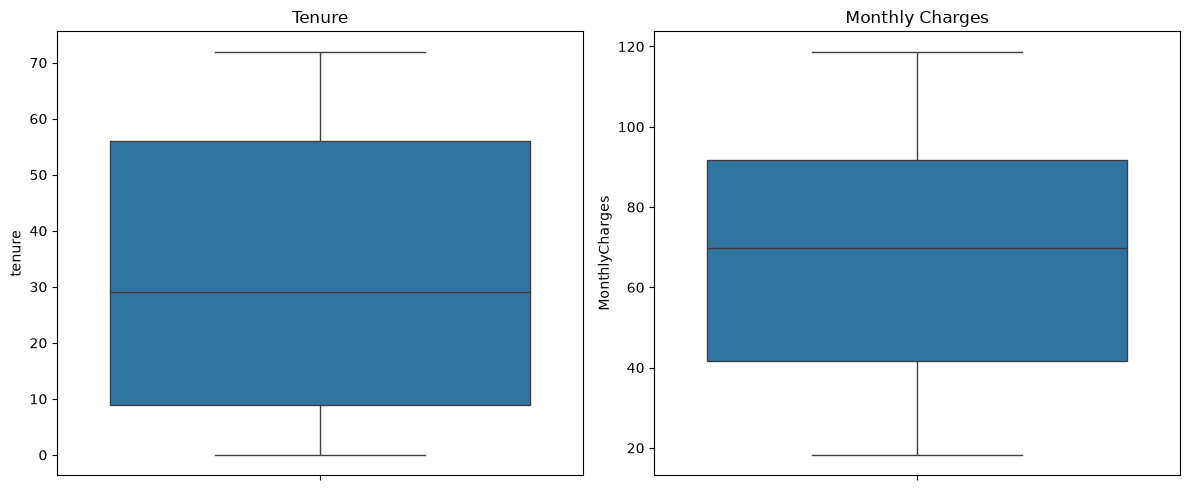

Name:Aditya Rade Roll No:BEAD23167


In [18]:
# Boxplots for numerical columns

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=data["tenure"])
plt.title("Tenure")

plt.subplot(1, 2, 2)
sns.boxplot(y=data["MonthlyCharges"])
plt.title("Monthly Charges")

plt.tight_layout()
plt.show()
print("Name:Aditya Rade Roll No:BEAD23167")